## Student Retention Project



### Overview

This longitudinal panel dataset is designed to support predictive modeling, risk profiling, and machine learning research focused on higher-education student retention.

It contains 79,239 synthetic semester-level records, tracking students across multiple academic terms for up to 8 semesters. The dataset captures a holistic view of the student experience by combining:

* Demographic information
* Socioeconomic and financial constraints
* Academic performance
* Semester-level progression
* Learning engagement indicators
* Attrition and retention risk factors

The primary objective is to model the probability of future student attrition through the target variable:
`Target_Dropout_Next_Sem`


Data set could be found at: https://www.kaggle.com/datasets/razanihababdellatif/student-retention-and-academic-performance-data

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import seaborn as sns
import numpy as np
import scipy
from scipy import stats
import plotly.express as px

### Read data set from CSV

In [2]:
# Read CSV
CSV_PATH = "academic_survival_longitudinal.csv"

df_raw = pd.read_csv(CSV_PATH)
print("Data set shape (rows, cols): ", df_raw.shape)

number_of_students = df_raw["Student_ID"].nunique()
print("Number of students: ", number_of_students)

tracked_semesters = df_raw["Semester"].nunique()
print("Number of tracked semesters: ", tracked_semesters)

display(df_raw.head())

Data set shape (rows, cols):  (79239, 22)
Number of students:  20000
Number of tracked semesters:  8


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


### Data cleaning and processing

In this section we review the dataset columns and perform any necessary cleaning steps. We display the data types and check for the missing values and do small transformations if that is the case.

In [3]:
# Make a data frame copy to work on it
df = df_raw.copy()

In [4]:
# Display data information
no_rows = df.shape[0]
no_colums = df.shape[1]
print("Number of rows: ", no_rows)
print("Number of columns: ", no_colums, '\n')
print("Dataframe columns and types: ", '\n')
df.dtypes

Number of rows:  79239
Number of columns:  22 

Dataframe columns and types:  



,0
Student_ID,object
Age,int64
Gender,object
First_Generation,int64
Family_Income,float64
Household_Size,int64
Housing_Status,object
Scholarship,int64
Tuition_Base,int64
Semester,int64


In [5]:
df.describe()

,Age,First_Generation,Family_Income,Household_Size,Scholarship,Tuition_Base,Semester,Course_Load,Work_Hours,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,Censored
count,79239.000000,79239.000000,75635.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,78372.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000
mean,19.492005,0.327894,61518.384346,3.187547,0.277515,24775.110741,3.145673,14.888615,16.936129,200.496788,2.691463,85.081599,66.375670,0.477530,0.652494,2.578287,0.087293,0.140272
std,2.139140,0.469449,39661.166570,1.332861,0.447775,10794.899387,1.946207,2.307308,10.724479,724.400513,0.422692,6.415864,12.730793,0.671954,0.786066,1.817880,0.282266,0.347271
min,17.000000,0.000000,3000.000000,1.000000,0.000000,15000.000000,1.000000,9.000000,0.000000,0.000000,0.440000,-2.000000,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,18.000000,0.000000,35000.000000,2.000000,0.000000,15000.000000,1.000000,12.000000,8.300000,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,19.000000,0.000000,52000.000000,3.000000,0.000000,25000.000000,3.000000,15.000000,16.500000,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,0.000000
75%,21.000000,1.000000,77000.000000,4.000000,1.000000,25000.000000,4.000000,15.000000,24.900000,0.000000,2.960000,89.200000,75.000000,1.000000,1.000000,3.400000,0.000000,0.000000
max,37.000000,1.000000,488000.000000,6.000000,1.000000,45000.000000,8.000000,21.000000,40.000000,3998.000000,3.960000,105.000000,116.000000,3.000000,5.000000,18.600000,1.000000,1.000000


In [6]:
df.describe().T[['min', 'max']]

,min,max
Age,17.00,37.00
First_Generation,0.00,1.00
Family_Income,3000.00,488000.00
Household_Size,1.00,6.00
Scholarship,0.00,1.00
Tuition_Base,15000.00,45000.00
Semester,1.00,8.00
Course_Load,9.00,21.00
Work_Hours,0.00,40.00
Emergency_Expense,0.00,3998.00


Attendance represents the percentage of classes attended. There are some weird values going below 0 and some going over 100, which it basically impossible, so we'll clip that the valid range of numbers.

In [7]:
# Clip attandance values to 0-100 range
out_of_range = (df["Attendance"] < 0) | (df["Attendance"] > 100)
df['Attendance'] = df['Attendance'].clip(0, 100)

In [8]:
# Convert categorical columns to category dtype
categorical_columns = ['Student_ID', 'Gender', 'Housing_Status', 'End_of_Semester_Status']
for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype('category')

display(df.dtypes)

,0
Student_ID,category
Age,int64
Gender,category
First_Generation,int64
Family_Income,float64
Household_Size,int64
Housing_Status,category
Scholarship,int64
Tuition_Base,int64
Semester,int64


In [9]:
# Check for missing values
missing_values = df_raw.isnull().sum()
print("Missing values based on columns: \n")
display(missing_values[missing_values > 0])

#Check for duplicated rows
dup_rows = df.duplicated()
print("Number of duplicated rows:", dup_rows.sum())

Missing values based on columns: 



,0
Family_Income,3604
LMS_Logins,867


Number of duplicated rows: 0


Family_Income mean:  61518.38434587162
Family_Income median:  52000.0
Family_Income IQ1:  35000.0
Family_Income IQ3:  77000.0
Family_Income IQR:  42000.0
Family Income outliers:  3523


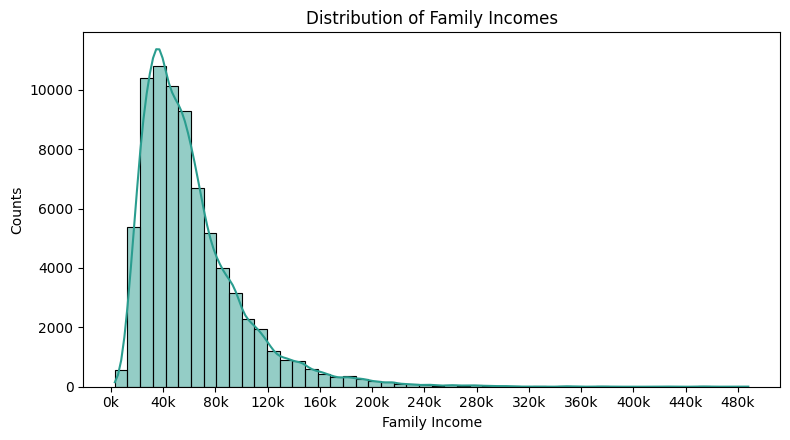

In [10]:
# Check Family Income values
print("Family_Income mean: ", df_raw["Family_Income"].mean())
print("Family_Income median: ", df_raw["Family_Income"].median())
family_income_q1 = df_raw["Family_Income"].quantile(0.25)
family_income_q3 = df_raw["Family_Income"].quantile(0.75)
print("Family_Income IQ1: ", family_income_q1)
print("Family_Income IQ3: ", family_income_q3)
family_income_iqr = family_income_q3 - family_income_q1
print("Family_Income IQR: ", family_income_iqr)

# Check for outliers for family income
family_income_lower_bound = family_income_q1 - 1.5 * family_income_iqr
family_income_upper_bound = family_income_q3 + 1.5 * family_income_iqr

mask = (df_raw["Family_Income"] > family_income_upper_bound) | (df_raw["Family_Income"] < family_income_lower_bound)
n_outliers = mask.sum()
print("Family Income outliers: ", n_outliers)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='Family_Income', bins=50, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of Family Incomes', xlabel='Family Income', ylabel='Counts')
ax.xaxis.set_major_locator(MultipleLocator(40000))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

For family income there are about 3600 missing value out of the 79,000. Based on the distribution of the values, as seen above, we will use the median value in order to fill the missing data. The median is the perfect choice here because the distribution is right-skewed, because it is robust to the tail and represents a typical family better. The mean would shift a chunk of data upward, as the mean was pulled up due to the long right tail.

In [11]:
# Clean Family_Income missing values

# Add column to flag missing family income
df["Family_Income_Missing"] = df_raw["Family_Income"].isna().astype(int)

display(df[df["Family_Income_Missing"] > 0])
median_family_income = df["Family_Income"].median()
df["Family_Income"] = df["Family_Income"].fillna(median_family_income)
display(df[df["Family_Income_Missing"] > 0])

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing
8,STU_00003,24,Male,1,NaN,3,On-Campus,0,15000,2,...,2.97,87.6,80.0,1,0,1.2,0,Enrolled,0,1
31,STU_00010,20,Male,0,NaN,5,With Parents,0,25000,3,...,2.93,86.1,72.0,0,1,1.0,1,Dropped_Out,0,1
139,STU_00034,18,Male,1,NaN,6,Off-Campus,0,15000,4,...,2.94,88.4,64.0,0,0,2.9,0,Enrolled,0,1
176,STU_00043,24,Female,1,NaN,1,On-Campus,0,25000,4,...,2.09,78.6,57.0,0,4,1.0,1,Dropped_Out,0,1
177,STU_00044,17,Male,0,NaN,5,On-Campus,1,15000,1,...,3.24,91.1,74.0,0,1,1.5,0,Enrolled,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79185,STU_19987,22,Female,0,NaN,3,On-Campus,1,15000,3,...,3.13,84.3,77.0,0,0,1.0,0,Enrolled,1,1
79192,STU_19989,19,Female,1,NaN,4,Off-Campus,0,25000,2,...,2.86,89.8,36.0,0,1,1.0,0,Enrolled,0,1
79204,STU_19991,18,Male,1,NaN,3,Off-Campus,0,15000,4,...,2.49,89.3,53.0,1,0,1.0,0,Enrolled,0,1
79209,STU_19992,24,Male,0,NaN,3,On-Campus,0,25000,4,...,2.79,88.3,55.0,0,2,1.0,0,Enrolled,0,1


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing
8,STU_00003,24,Male,1,52000.0,3,On-Campus,0,15000,2,...,2.97,87.6,80.0,1,0,1.2,0,Enrolled,0,1
31,STU_00010,20,Male,0,52000.0,5,With Parents,0,25000,3,...,2.93,86.1,72.0,0,1,1.0,1,Dropped_Out,0,1
139,STU_00034,18,Male,1,52000.0,6,Off-Campus,0,15000,4,...,2.94,88.4,64.0,0,0,2.9,0,Enrolled,0,1
176,STU_00043,24,Female,1,52000.0,1,On-Campus,0,25000,4,...,2.09,78.6,57.0,0,4,1.0,1,Dropped_Out,0,1
177,STU_00044,17,Male,0,52000.0,5,On-Campus,1,15000,1,...,3.24,91.1,74.0,0,1,1.5,0,Enrolled,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79185,STU_19987,22,Female,0,52000.0,3,On-Campus,1,15000,3,...,3.13,84.3,77.0,0,0,1.0,0,Enrolled,1,1
79192,STU_19989,19,Female,1,52000.0,4,Off-Campus,0,25000,2,...,2.86,89.8,36.0,0,1,1.0,0,Enrolled,0,1
79204,STU_19991,18,Male,1,52000.0,3,Off-Campus,0,15000,4,...,2.49,89.3,53.0,1,0,1.0,0,Enrolled,0,1
79209,STU_19992,24,Male,0,52000.0,3,On-Campus,0,25000,4,...,2.79,88.3,55.0,0,2,1.0,0,Enrolled,0,1


LMS_Login mean:  66.37566988210075
LMS_Login median:  66.0
LMS_Logins outliers:  600


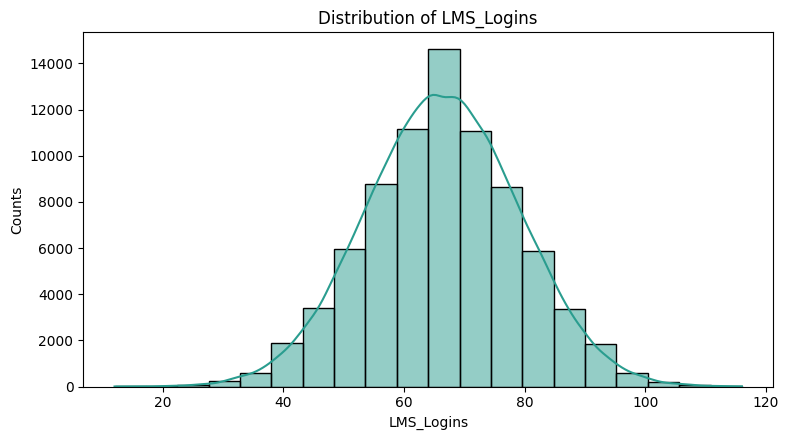

In [12]:
# Check LMS Logins values

print("LMS_Login mean: ", df_raw["LMS_Logins"].mean())
print("LMS_Login median: ", df_raw["LMS_Logins"].median())
lms_logins_q1 = df_raw["LMS_Logins"].quantile(0.25)
lms_logins_q3 = df_raw["LMS_Logins"].quantile(0.75)
lms_logins_iqr = lms_logins_q3 - lms_logins_q1

lms_logins_lower_bound = lms_logins_q1 - 1.5 * lms_logins_iqr
lms_logins_upper_bound = lms_logins_q3 + 1.5 * lms_logins_iqr

mask = (df_raw["LMS_Logins"] > lms_logins_upper_bound) | (df_raw["LMS_Logins"] < lms_logins_lower_bound)
n_outliers = mask.sum()
print("LMS_Logins outliers: ", n_outliers)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='LMS_Logins', bins=20, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of LMS_Logins', xlabel='LMS_Logins', ylabel='Counts')
plt.tight_layout()
plt.show()

LMS Logins values have a normal distribution, also the mean is almost equal to the median. Because it doesnt present a skew-like distribution and the amount of outliers (600) compared to the total number of values (79,000) is low, we'll use the mean value to fill the missing values.

In [13]:
# Clean LMS Logins missing values

# Add column to flag missing LMS Logins
df["LMS_Logins_Missing"] = df_raw["LMS_Logins"].isna().astype(int)

display(df[df["LMS_Logins_Missing"] > 0])
mean_lms_logins = df["LMS_Logins"].mean()
df["LMS_Logins"] = df["LMS_Logins"].fillna(mean_lms_logins)
display(df[df["LMS_Logins_Missing"] > 0])

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing,LMS_Logins_Missing
84,STU_00022,18,Female,0,89000.0,3,With Parents,0,15000,2,...,84.6,NaN,1,0,1.0,0,Enrolled,0,0,1
184,STU_00047,18,Female,0,28000.0,2,On-Campus,0,15000,2,...,86.3,NaN,1,1,5.4,0,Enrolled,0,0,1
271,STU_00075,17,Male,0,55000.0,2,Off-Campus,0,15000,3,...,82.9,NaN,1,0,1.7,0,Enrolled,0,0,1
509,STU_00132,24,Female,0,56000.0,4,Off-Campus,0,25000,3,...,94.9,NaN,0,0,1.0,0,Enrolled,0,0,1
547,STU_00142,18,Female,0,88000.0,2,On-Campus,0,25000,5,...,83.4,NaN,0,2,1.0,0,Enrolled,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78808,STU_19900,19,Female,0,21000.0,3,With Parents,0,25000,2,...,74.2,NaN,1,1,4.8,0,Enrolled,0,0,1
78895,STU_19917,23,Female,0,38000.0,6,On-Campus,1,25000,3,...,68.1,NaN,0,1,6.6,0,Enrolled,0,0,1
78924,STU_19923,19,Male,0,65000.0,4,Off-Campus,0,45000,6,...,85.1,NaN,2,0,2.7,0,Enrolled,0,0,1
79119,STU_19968,19,Female,0,75000.0,5,On-Campus,0,15000,5,...,87.4,NaN,0,1,2.4,0,Enrolled,0,0,1


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing,LMS_Logins_Missing
84,STU_00022,18,Female,0,89000.0,3,With Parents,0,15000,2,...,84.6,66.37567,1,0,1.0,0,Enrolled,0,0,1
184,STU_00047,18,Female,0,28000.0,2,On-Campus,0,15000,2,...,86.3,66.37567,1,1,5.4,0,Enrolled,0,0,1
271,STU_00075,17,Male,0,55000.0,2,Off-Campus,0,15000,3,...,82.9,66.37567,1,0,1.7,0,Enrolled,0,0,1
509,STU_00132,24,Female,0,56000.0,4,Off-Campus,0,25000,3,...,94.9,66.37567,0,0,1.0,0,Enrolled,0,0,1
547,STU_00142,18,Female,0,88000.0,2,On-Campus,0,25000,5,...,83.4,66.37567,0,2,1.0,0,Enrolled,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78808,STU_19900,19,Female,0,21000.0,3,With Parents,0,25000,2,...,74.2,66.37567,1,1,4.8,0,Enrolled,0,0,1
78895,STU_19917,23,Female,0,38000.0,6,On-Campus,1,25000,3,...,68.1,66.37567,0,1,6.6,0,Enrolled,0,0,1
78924,STU_19923,19,Male,0,65000.0,4,Off-Campus,0,45000,6,...,85.1,66.37567,2,0,2.7,0,Enrolled,0,0,1
79119,STU_19968,19,Female,0,75000.0,5,On-Campus,0,15000,5,...,87.4,66.37567,0,1,2.4,0,Enrolled,0,0,1


In [14]:
display(df_raw["Gender"].value_counts())

# Gender values are not consistent
gender_map = {
    'female': 'Female', 'f': 'Female',
    'male': 'Male', 'm': 'Male',
    'other': 'Other',
    'prefer not to say': 'Prefer not to say',
}
df['Gender'] = df_raw['Gender'].str.strip().str.lower().map(gender_map)
display(df['Gender'].value_counts(dropna=False))

,count
Gender,
Female,38035
Male,36556
Other,1125
female,875
male,764
M,739
F,716
Prefer not to say,429


,count
Gender,
Female,39626
Male,38059
Other,1125
Prefer not to say,429


General exploratory analysis uses the full cleaned dataset. Analyses involving dropout or outcome status use records with Censored = 0. This subset is our chosen analysis convention. First-semester comparisons and visualization samples apply additional restrictions, stated where used.

In [15]:
# Full cleaned dataset: use df for general EDA.
# Project convention: use uncensored records for dropout-related analyses.
target = "Target_Dropout_Next_Sem"
df_dropout = df.loc[df["Censored"].eq(0)].copy()

print(f"Full dataset: {len(df):,} student-semester records")
print(f"Dropout analysis: {len(df_dropout):,} student-semester records")
print(f"Dropout events: {df_dropout[target].sum():,}")
print(f"Dropout percentage: {df_dropout[target].mean():.2%}")

Full dataset: 79,239 student-semester records
Dropout analysis: 68,124 student-semester records
Dropout events: 6,917
Dropout percentage: 10.15%


### Exploratory Data Analysis

Now, we have our clean data, we'll perform EDA (Exploratory Data Analysis). We are going to use a various method to visualize the data from multiple perspectives such as demographics, academic performance and financial aspect.

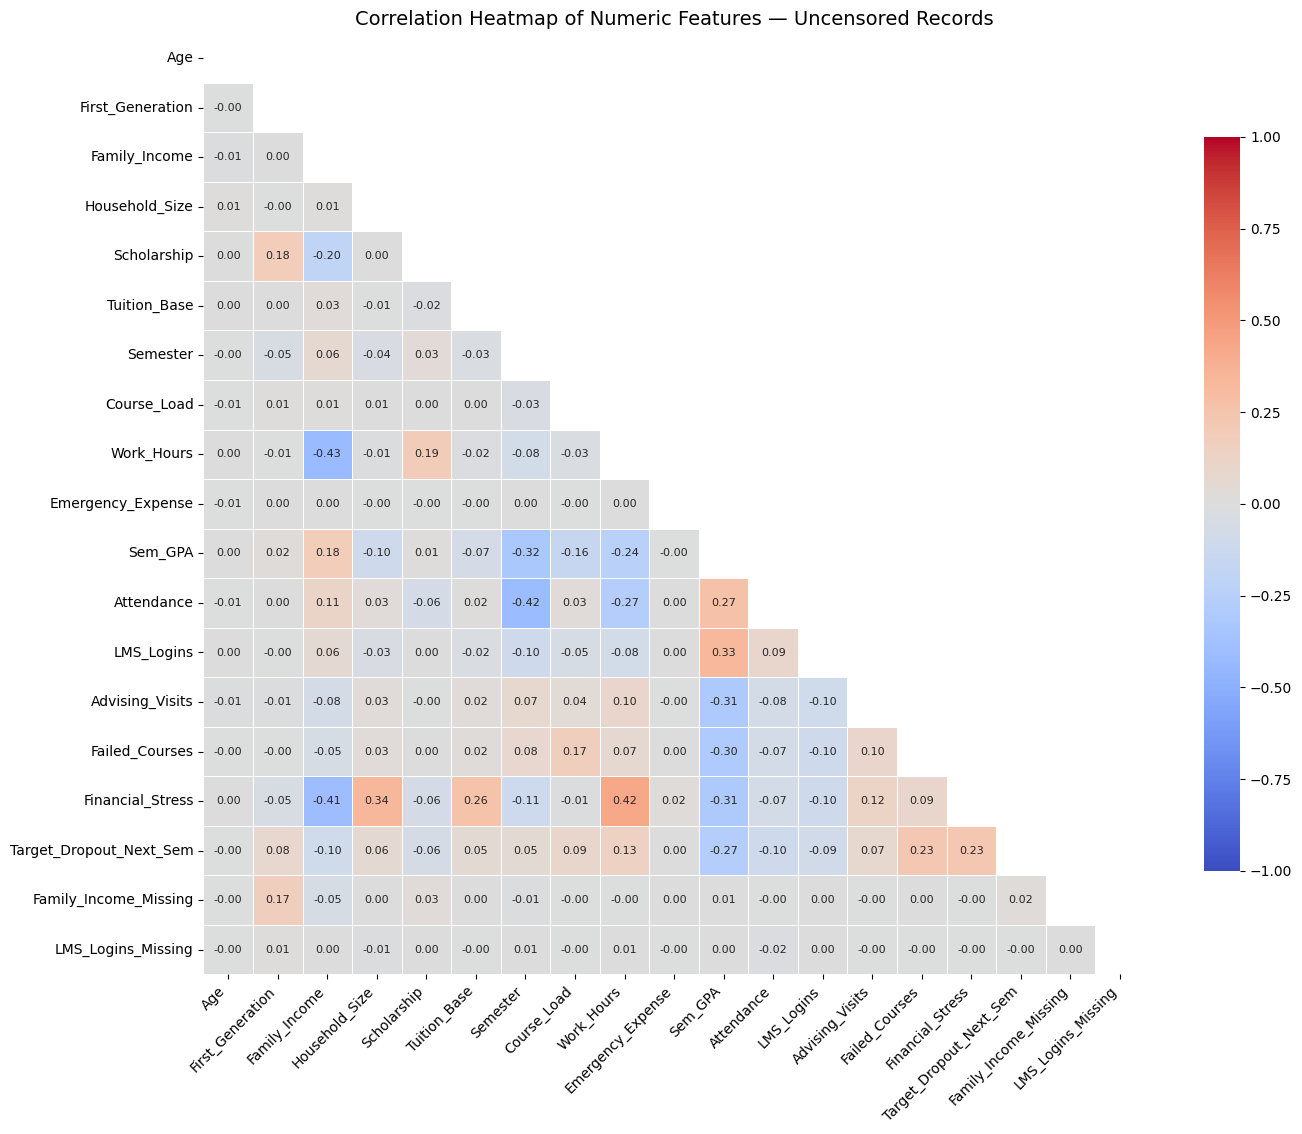

In [16]:
# # Correlations within the shared dropout-analysis sample. Select only numeric columns.
numeric_dropout = (
    df_dropout.select_dtypes(include=[np.number])
    .drop(columns="Censored")
    )

corr = numeric_dropout.corr()
# Hide only the upper triangle + diagonal
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,                 # display correlation value inside each square
    fmt='.2f',                  # each square contains 2 decimals
    annot_kws={'size': 8},      # size of annotation text
    cmap='coolwarm',
    vmin=-1, vmax=1, center=0,  # white = no correlation, red/blue = strong
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.7},
    ax=ax,
)

ax.grid(False)
ax.set_title('Correlation Heatmap of Numeric Features — Uncensored Records', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Explanation:
In regards to `Target_Dropout_Next_Sem` the features that more related are the following:
* `Sem_GPA` (r = -0.27) -> lower GPA, more chance to dropout (strongest signal)
* `Failed_Courses` (r = 0.23) -> more courses failed results in more dropout
* `Financial_Stress` (r = 0.23) -> financial pressure matters as much as failures
* `Work_Hours` (r = 0.13) -> more working hours, slightly more dropout

From all of this we can't really say that there is a strongly predictive feature as no there is no |r| > 0.3, but this results in dropout being impacted by multiple factors alltogether instead of a single one.

In [17]:
# Check Person correlation between the most important contributing features to check if any relationship was purely based on luck
def format_pvalue(value):
    if value == 0:
        return "below numerical precision"
    return f"{value:.2e}"

for col in [
    "Sem_GPA",
    "Failed_Courses",
    "Financial_Stress",
    "Work_Hours",
]:
    r_result = stats.pearsonr(
        df_dropout[col],
        df_dropout[target],
    )

    print(f"Relationship between {col:17s} and dropout -> Person r:{r_result.statistic:.3f} | p={format_pvalue(r_result.pvalue)}")


Relationship between Sem_GPA           and dropout -> Person r:-0.273 | p=below numerical precision
Relationship between Failed_Courses    and dropout -> Person r:0.231 | p=below numerical precision
Relationship between Financial_Stress  and dropout -> Person r:0.231 | p=below numerical precision
Relationship between Work_Hours        and dropout -> Person r:0.134 | p=5.31e-270


The`r` values suggest exactly what's inside the correlation heat map, while `p` here is 0 or close to 0. Since p is much smaller that `0.05` which means that it's almost impossible to see a relation this strong between these variables just by pure luck.

In [18]:
# Perform Welch's test on students to stay and on ones who dropout
sem1 = sem1 = df_dropout.loc[df_dropout["Semester"].eq(1)].copy()

print(f"First-semester records: {len(sem1):,}")
print(f"Dropout records: {sem1[target].sum():,}")
print(f"No-dropout records: {sem1[target].eq(0).sum():,}")

for col in ['Sem_GPA', 'Failed_Courses', 'Financial_Stress', 'Work_Hours',
            'Attendance', 'Family_Income', 'LMS_Logins']:
    group_a = sem1.loc[sem1[target] == 1, col].dropna().to_numpy()
    group_b = sem1.loc[sem1[target] == 0, col].dropna().to_numpy()

    t_result = stats.ttest_ind(group_a, group_b, equal_var=False)
    print(f"{col:17s} dropout={group_a.mean():9.2f}  stayed={group_b.mean():9.2f}  "
          f"t={t_result.statistic:7.3f}  p={t_result.pvalue:.2e}")

First-semester records: 17,928
Dropout records: 1,332
No-dropout records: 16,596
Sem_GPA           dropout=     2.52  stayed=     2.92  t=-31.113  p=3.27e-165
Failed_Courses    dropout=     1.11  stayed=     0.52  t= 22.065  p=3.08e-93
Financial_Stress  dropout=     4.42  stayed=     2.70  t= 20.118  p=2.25e-79
Work_Hours        dropout=    22.01  stayed=    17.54  t= 14.787  p=2.09e-46
Attendance        dropout=    87.69  stayed=    89.22  t= -9.561  p=4.30e-21
Family_Income     dropout= 47044.29  stayed= 59451.13  t=-13.561  p=8.23e-40
LMS_Logins        dropout=    64.98  stayed=    68.60  t=-10.012  p=6.58e-23


The Welch's T-test values displayed above as `t`, how bigger the impact of the specific feature has on dropout case compared to it's uncertainty. For example the GPA gap is 31 times larger than the uncertainty it provides, which means it can't plausibly be by chance.

The sign of the `t` variable gives us the direction, for example in case of: `Sem_GPA`, `Family_Income`, `LMS_Logins` and `Attendance`, if these go up, the dropout rate goes down (negative relationship). But in case of `Failed_Courses`, `Financial_Stress` and `Work_Hours`, as these go up in value, the dropout follows that trajectory (positive relationship).

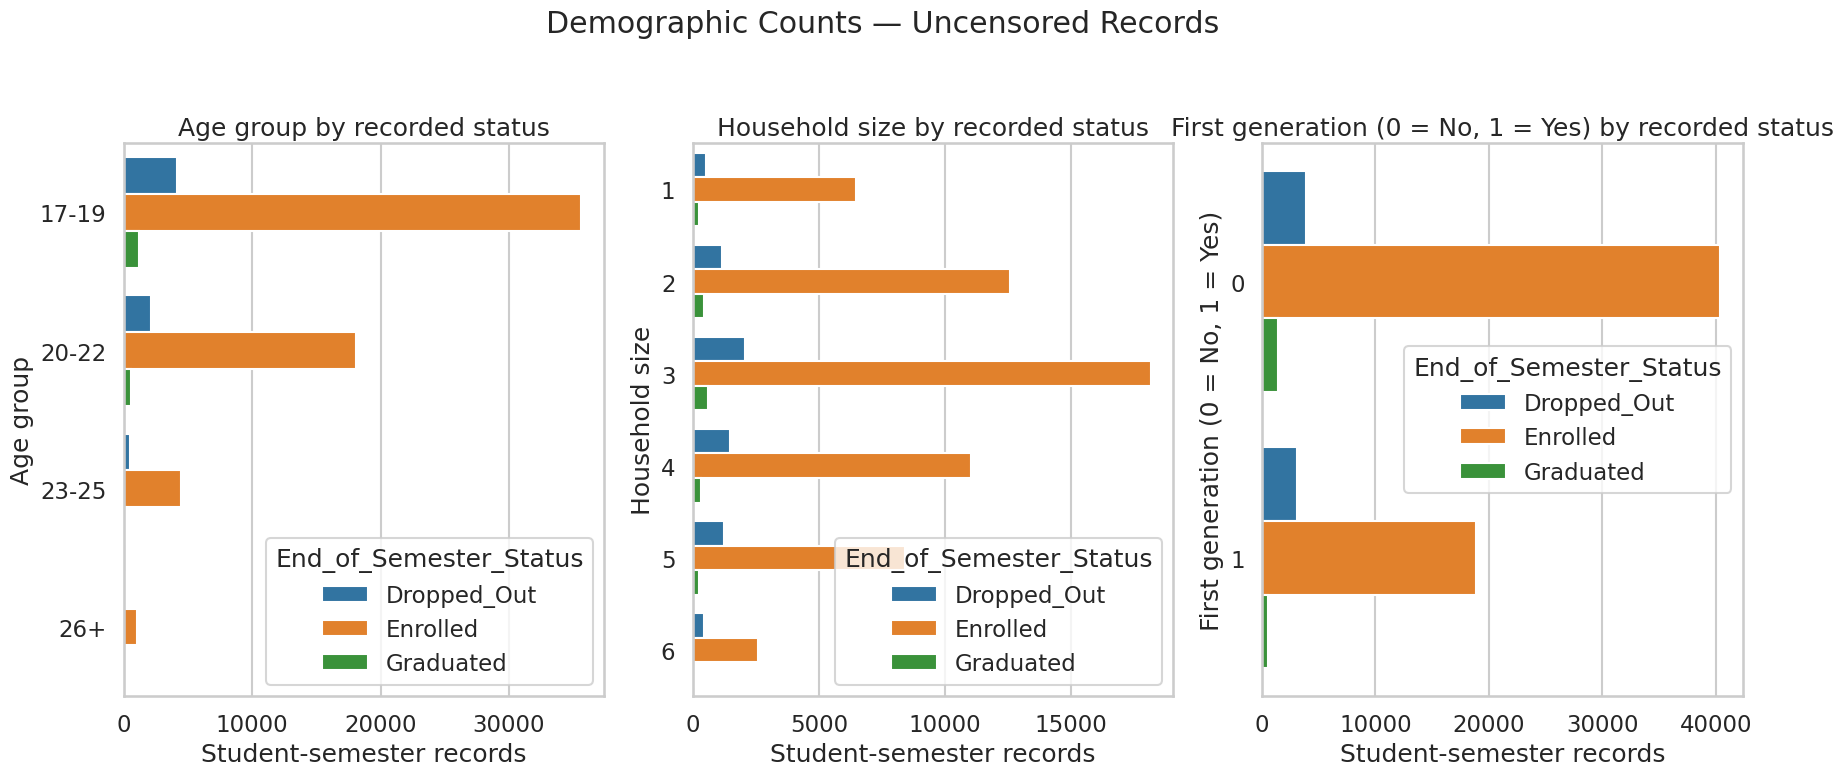

In [19]:
# Display count plots based on demographic, financial and academic performance properties
sns.set_style("whitegrid")
sns.set_context("talk")

demographics = df_dropout.copy()

demographics["Age_Group"] = pd.cut(
    demographics["Age"],
    bins=[16, 19, 22, 25, 40],
    labels=["17-19", "20-22", "23-25", "26+"],
)

columns = ["Age_Group", "Household_Size", "First_Generation"]
labels = {
    "Age_Group": "Age group",
    "Household_Size": "Household size",
    "First_Generation": "First generation (0 = No, 1 = Yes)",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, col in zip(axes, columns):
    sns.countplot(
        data=demographics,
        y=col,
        hue="End_of_Semester_Status",
        ax=ax,
    )

    ax.set(
        title=f"{labels[col]} by recorded status",
        xlabel="Student-semester records",
        ylabel=labels[col],
    )

fig.suptitle("Demographic Counts — Uncensored Records")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Based on the demographic charts above, most uncensored student semester records belong to the younger age groups. Households of three members contribute the largest number of records, and records from students who are not first-generation college students are more common than those from first-generation students. Across these demographic categories, the enrolled status accounts for most observations.
These charts describe the composition of our analysis sample. Because students can contribute multiple semester records, the bars do not represent unique-student counts. Larger dropout counts in a demographic group do not necessarily indicate greater dropout risk; comparing risk require calculating the dropout percentage within each group. This is shown in the sections below.

In [20]:
demographics = df_dropout.copy()

demographics["Age_Group"] = pd.cut(
    demographics["Age"],
    bins=[16, 19, 22, 25, np.inf],
    labels=["17-19", "20-22", "23-25", "26+"],
)

demographics["First_Generation_Label"] = pd.Categorical(
    demographics["First_Generation"].map({
        0: "Not first-generation",
        1: "First-generation",
    }),
    categories=["Not first-generation", "First-generation"],
    ordered=True,
)

demographic_specs = [
    ("Age group", "Age_Group"),
    ("Household size", "Household_Size"),
    ("First-generation status", "First_Generation_Label"),
]


def summarize_dropout(data, group_column):
    summary = (
        data.groupby(group_column, observed=True)[target]
        .agg(
            records="size",
            dropouts="sum",
            dropout_pct="mean",
        )
        .reset_index()
        .rename(columns={group_column: "group"})
    )

    summary["dropout_pct"] *= 100
    return summary


demographic_summaries = {}
demographic_tables = []

for name, column in demographic_specs:
    summary = summarize_dropout(demographics, column)
    demographic_summaries[name] = summary

    table = summary.copy()
    table.insert(0, "demographic", name)
    demographic_tables.append(table)

demographic_table = pd.concat(
    demographic_tables,
    ignore_index=True,
)

print("Dropout percentages within uncensored demographic groups")
display(demographic_table.round({"dropout_pct": 2}))

Dropout percentages within uncensored demographic groups


,demographic,group,records,dropouts,dropout_pct
0,Age group,17-19,40985,4159,10.15
1,Age group,20-22,20795,2116,10.18
2,Age group,23-25,5141,520,10.11
3,Age group,26+,1203,122,10.14
4,Household size,1,7263,531,7.31
5,Household size,2,14214,1166,8.20
6,Household size,3,20806,2076,9.98
7,Household size,4,12823,1456,11.35
8,Household size,5,9911,1245,12.56
9,Household size,6,3107,443,14.26


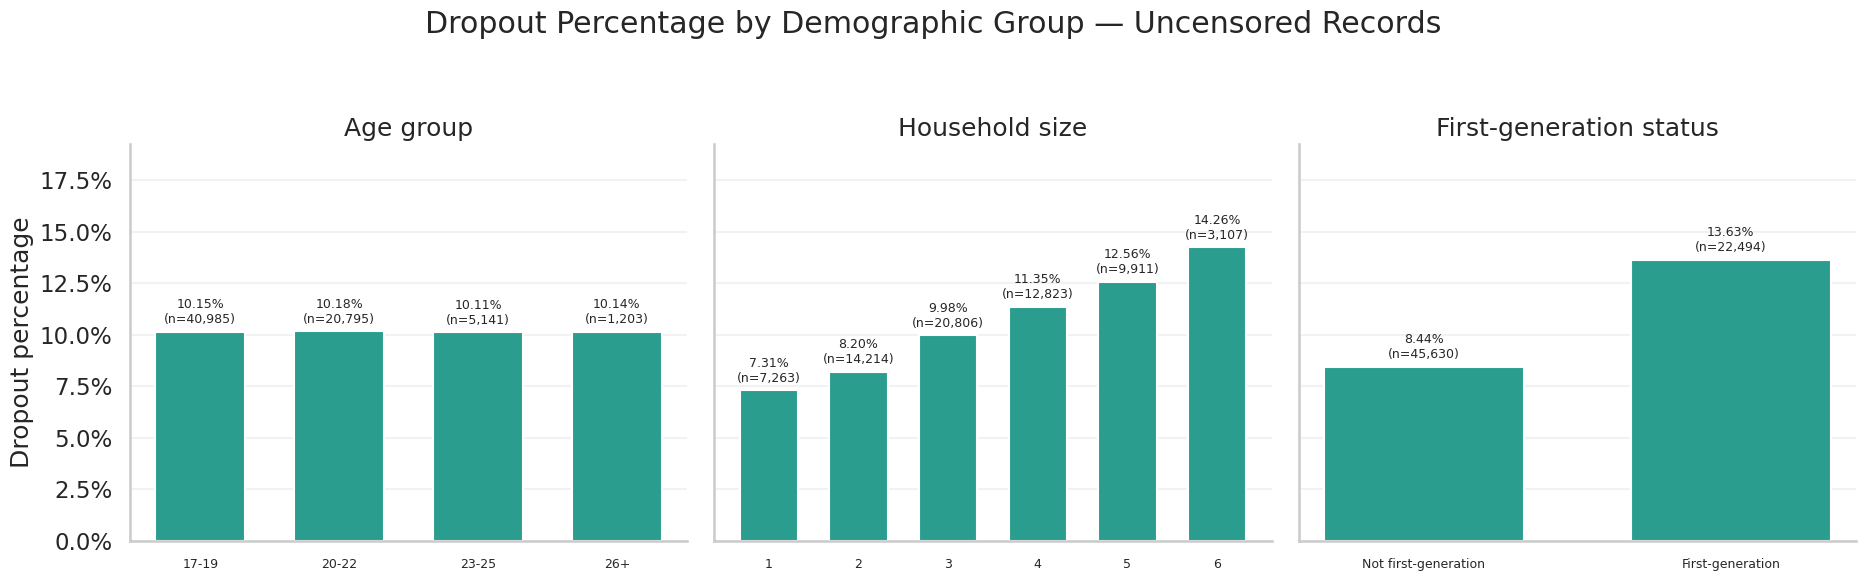

In [21]:
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6),
    sharey=True,
)

maximum_rate = max(
    summary["dropout_pct"].max()
    for summary in demographic_summaries.values()
)

for ax, (name, summary) in zip(
    axes,
    demographic_summaries.items(),
):
    positions = np.arange(len(summary))

    bars = ax.bar(
        positions,
        summary["dropout_pct"],
        color="#2A9D8F",
        width=0.65,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        summary["group"].astype(str),
        fontsize=9,
    )

    bar_labels = [
        f"{rate:.2f}%\n(n={records:,})"
        for rate, records in zip(
            summary["dropout_pct"],
            summary["records"],
        )
    ]

    ax.bar_label(
        bars,
        labels=bar_labels,
        padding=4,
        fontsize=9,
    )

    ax.set_title(name)
    ax.set_ylim(0, maximum_rate * 1.35)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

    ax.grid(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Dropout percentage")

fig.suptitle(
    "Dropout Percentage by Demographic Group — Uncensored Records"
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Dropout percentages are nearly identical across the age groups, despite their different sizes. In contrast, dropout percentages increase with household size and are higher among first-generation records.

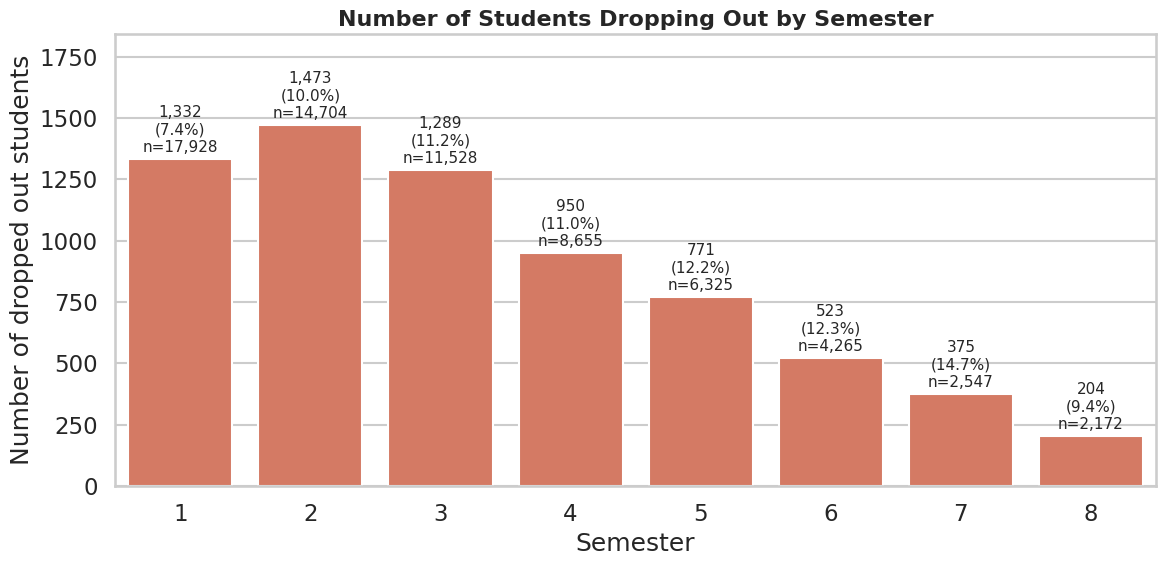

In [22]:
sns.set_style("whitegrid")
sns.set_context("talk")

sem_drop = (
    df_dropout
      .groupby('Semester')[target]
      .agg(dropouts='sum', students='size', dropout_rate='mean')
      .reset_index()
)
sem_drop['dropout_rate'] *= 100

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=sem_drop, x='Semester', y='dropouts', color='#E76F51', ax=ax)

# Label each bar with the dropout count and the rate
labels = [f"{d:,}\n({r:.1f}%)\nn={n:,}"
          for d, r, n in zip(sem_drop['dropouts'], sem_drop['dropout_rate'], sem_drop['students'])]
ax.bar_label(ax.containers[0], labels=labels, fontsize=11, padding=3)

ax.set_title("Number of Students Dropping Out by Semester", fontsize=16, fontweight='bold')
ax.set_xlabel("Semester")
ax.set_ylabel("Number of dropped out students")
ax.set_ylim(0, sem_drop['dropouts'].max() * 1.25)   # make room on top for the bar labels

plt.tight_layout()
plt.show()

The chart shows the most number of students dropping out is in the first three semesters (the second one having the most dropouts). However, the biggest percentage of dropouts is found in 7th semester (375 out of 2,547 , which is around 14.7%). Even with this, the first 3 semesters should be considered high risk, because the number of the students are more important than the percentages.

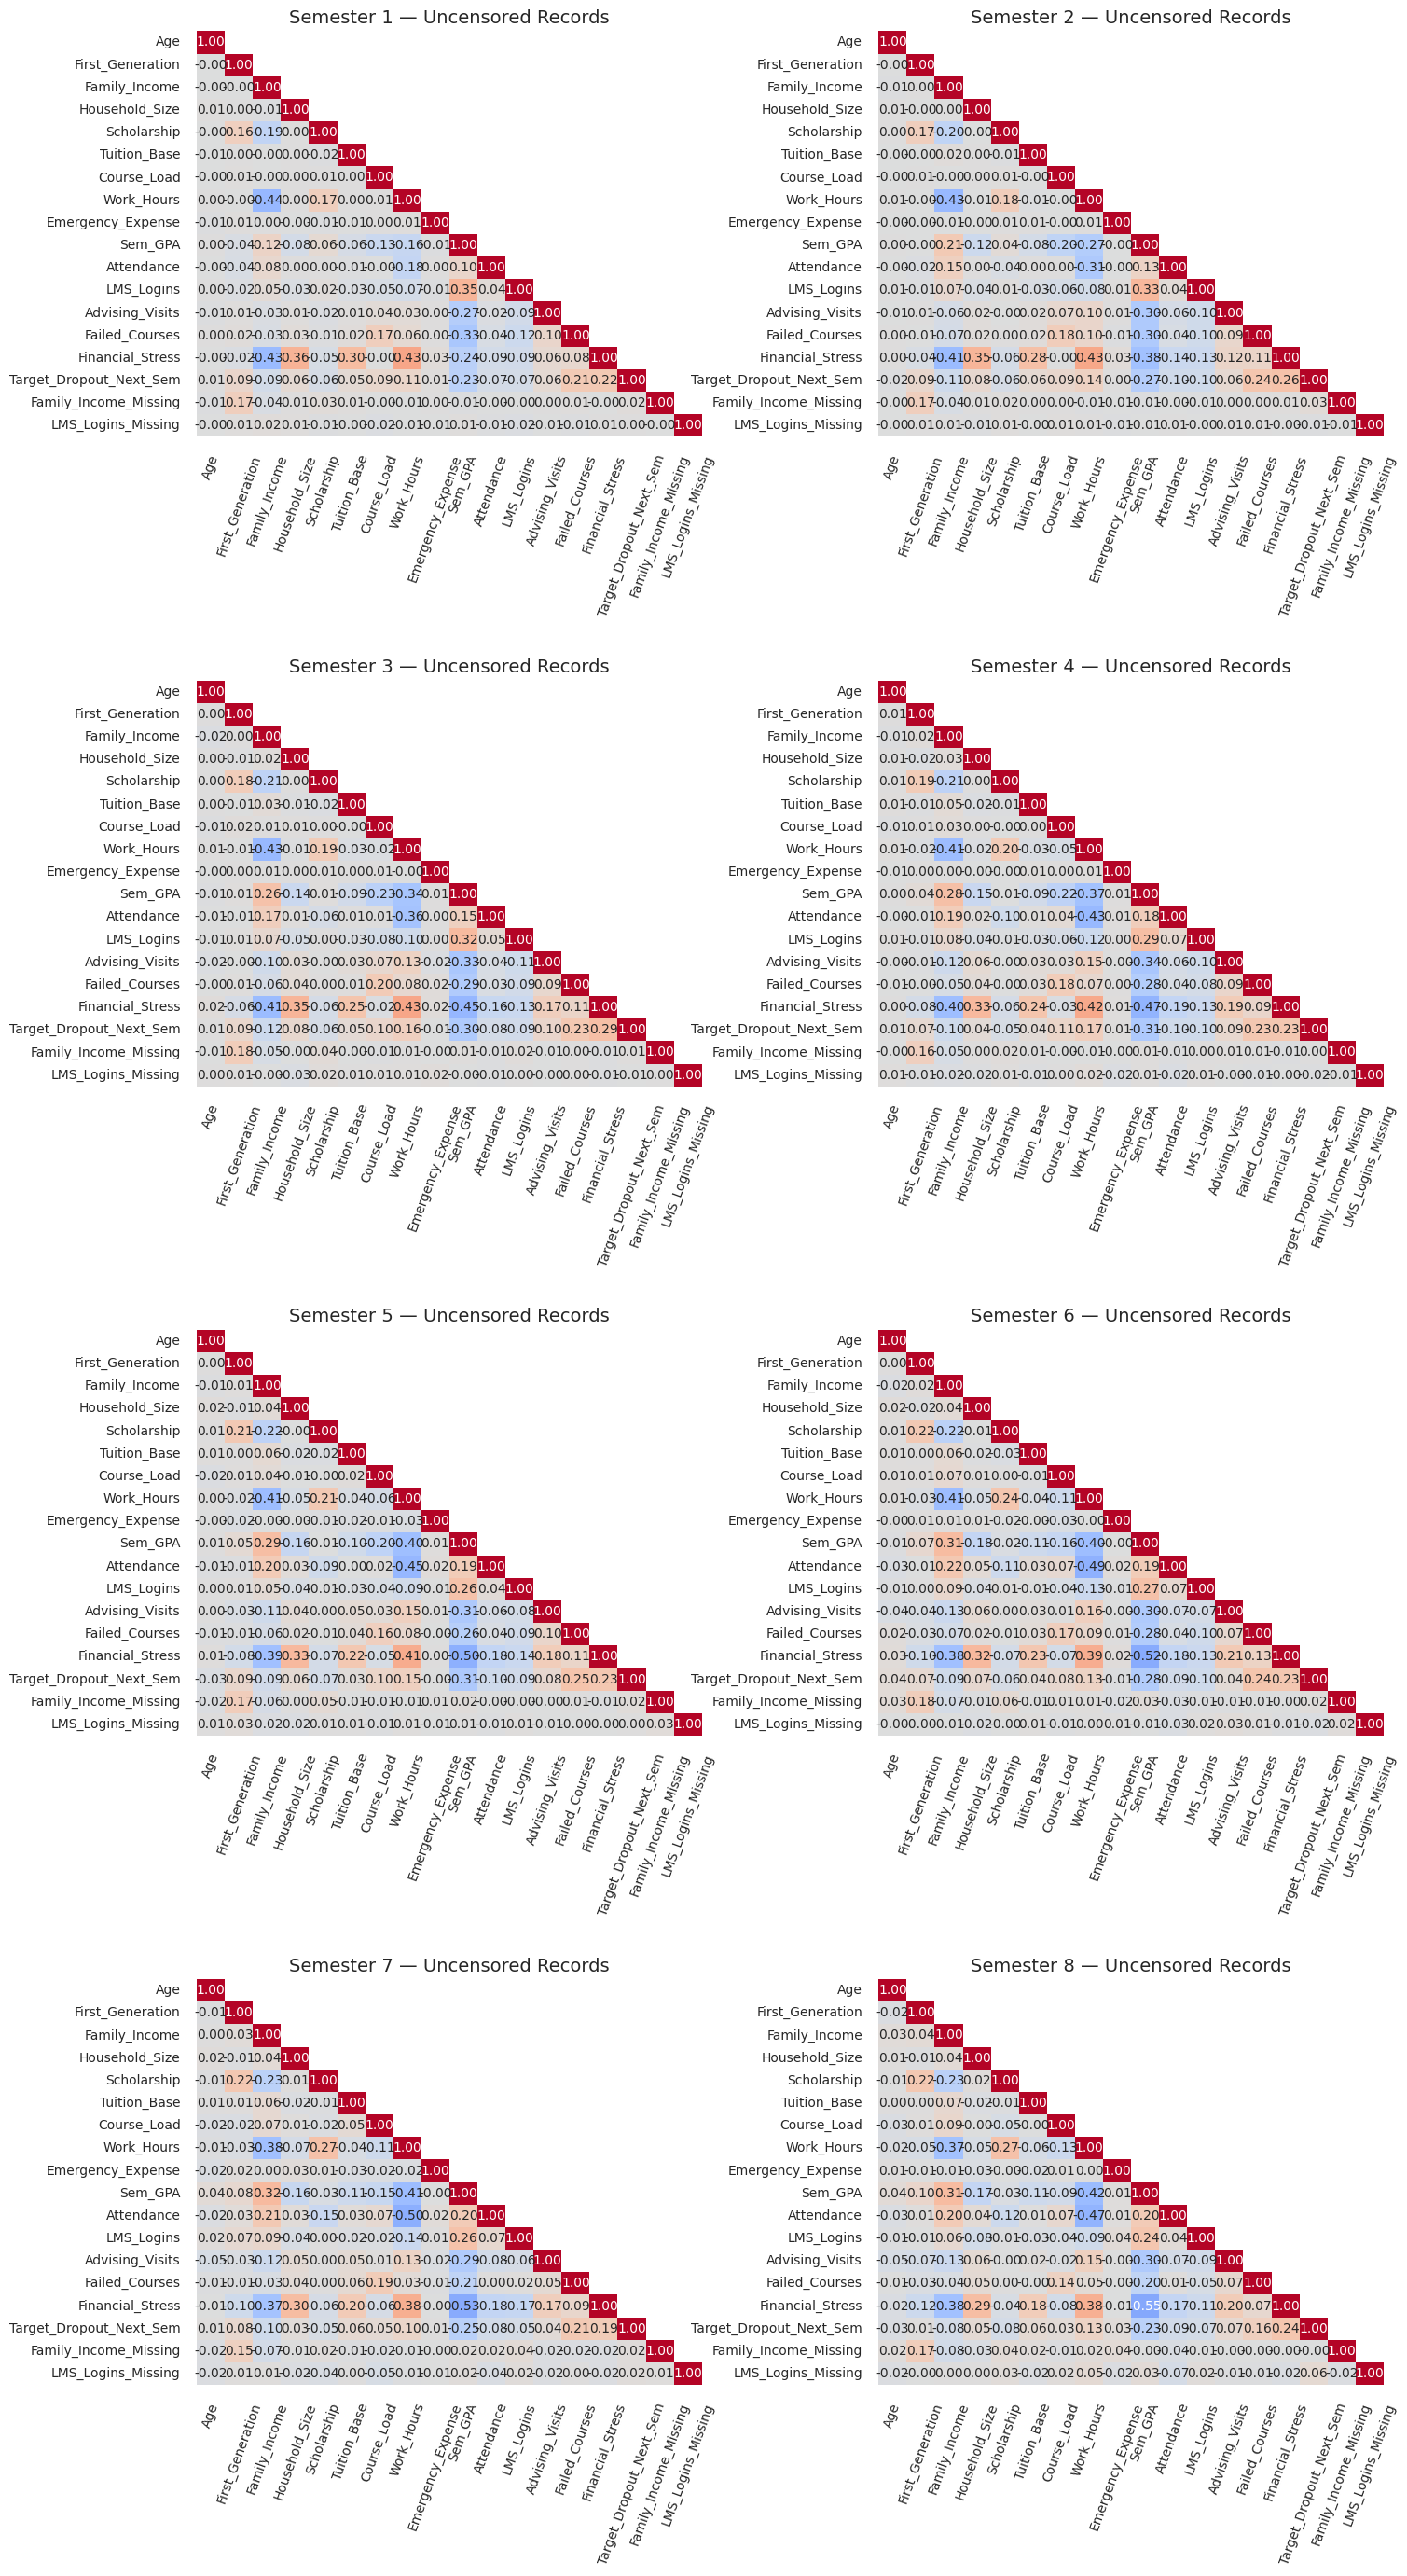

In [23]:
#WHAT Happened in semester 1,2 and 6 ***************

# Semester-specific correlations within the uncensored analysis sample.
semester_numeric = (
    df_dropout.select_dtypes(include=[np.number])
    .drop(columns="Censored")
)

def correlation_heatmap(data, **kwargs):
    corr = data.drop(columns="Semester", errors="ignore").corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    ax = plt.gca()

    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 10},
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        cbar=False,
        ax=ax,
    )

    ax.grid(False)
    ax.tick_params(axis="x", labelsize=10, labelrotation=70)
    ax.tick_params(axis="y", labelsize=10, labelrotation=0)

g = sns.FacetGrid(
    semester_numeric,
    col="Semester",
    col_order=sorted(semester_numeric["Semester"].unique()),
    col_wrap=2,       # Two columns × two rows for eight semesters.
    height=7,
    aspect=1.1,
    sharex=False,
    sharey=False,
)

g.map_dataframe(correlation_heatmap)
g.set_titles("Semester {col_name} — Uncensored Records", size=14)

g.fig.subplots_adjust(hspace=0.6, wspace=0.35)

plt.show()


In [24]:
sample = df_dropout.sample(frac=0.1, random_state=42).copy()
sample['Failed_Size'] = sample['Failed_Courses'] + 1   # size can't be 0, or the point disappears

fig = px.scatter(
    sample, x='Attendance', y='Sem_GPA',
    color='End_of_Semester_Status', size='Failed_Size',
    hover_data=['Student_ID', 'Semester', 'Failed_Courses', 'Work_Hours', 'Financial_Stress'],
    labels={'Attendance': 'Attendance (%)', 'Sem_GPA': 'Semester GPA',
            'Failed_Size': 'Failed courses (+1)'},
    category_orders={'End_of_Semester_Status': ['Enrolled', 'Dropped_Out', 'Graduated']},
    opacity=0.6,
    title='Interactive GPA and Attendance Explorer',
    template='plotly_white'
)
fig.update_layout(legend_title_text='End of Semester Status')
fig.show()

The plotly scatter plot shows the Attendace rate vs GPA and the size of the data points is given by the amount of failed courses. We can notice that even high attendance could result in a dropout. Also even a high GPA combined with high attendence and lower failed class could result in a dropout.

Insights:
* If student has low GPA + more than 2-3 failed courses, there is a high probability of dropout
* On the other hand, if student has high GPA, does not fail more than 1-2 courses, but the financial stress is higher, that also increases the risk of dropout.

Usually if the GPA is lower than 2.5, there is high risk of dropout. Most of the samples in this range tend to not continue the next semester.

,gpa_range,records,dropouts,dropout_rate
0,"(0.25, 0.5]",1,1,100.00
1,"(0.5, 0.75]",14,9,64.29
2,"(0.75, 1.0]",56,34,60.71
3,"(1.0, 1.25]",163,101,61.96
4,"(1.25, 1.5]",403,222,55.09
5,"(1.5, 1.75]",960,419,43.65
6,"(1.75, 2.0]",2261,748,33.08
7,"(2.0, 2.25]",5378,1118,20.79
8,"(2.25, 2.5]",11465,1517,13.23
9,"(2.5, 2.75]",17297,1485,8.59


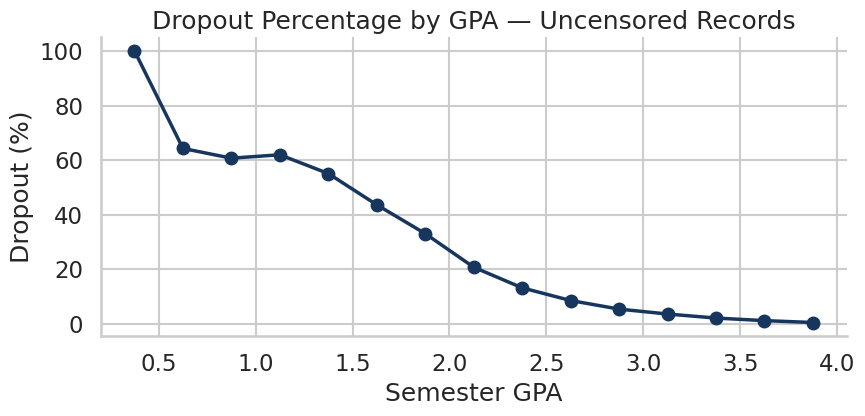

Records with GPA below 2.5: 20,048
Dropout events in this group: 4,103
Dropout percentage in this group: 20.47%


In [25]:
gpa = df_dropout.copy()

gpa["gpa_range"] = pd.cut(
    gpa["Sem_GPA"],
    bins=np.arange(0, 4.25, 0.25),
)

gpa_dropout = (
    gpa.groupby("gpa_range", observed=True)[target]
    .agg(
        records="size",
        dropouts="sum",
        dropout_rate="mean",
    )
    .reset_index()
)

gpa_dropout["dropout_rate"] *= 100
display(gpa_dropout.round({"dropout_rate": 2}))

midpoints = [interval.mid for interval in gpa_dropout["gpa_range"]]

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    midpoints,
    gpa_dropout["dropout_rate"],
    marker="o",
    linewidth=2.5,
    color="#17365D",
)

ax.set(
    title="Dropout Percentage by GPA — Uncensored Records",
    xlabel="Semester GPA",
    ylabel="Dropout (%)",
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

below_25 = df_dropout.loc[df_dropout["Sem_GPA"].lt(2.5)]

print(f"Records with GPA below 2.5: {len(below_25):,}")
print(f"Dropout events in this group: {below_25[target].sum():,}")
print(f"Dropout percentage in this group: {below_25[target].mean():.2%}")

The line chart between GPA and Dropout rate shows that the dropout percentages generally decrease as GPA increases. There is a negative relationship between GPA and Dropout rate. The lowest GPA interval contains only one record, producing a 100% dropout percentage that should not be generalized. The interval counts help distinguish patterns supported by many records from percentages based on small groups.
Among uncensored records with GPA below 2.5, 4,103 of 20,048 records are labeled as dropout, or approximately 20.5%. Lower GPA is associated with a higher observed dropout percentage, but it does not determine the outcome.

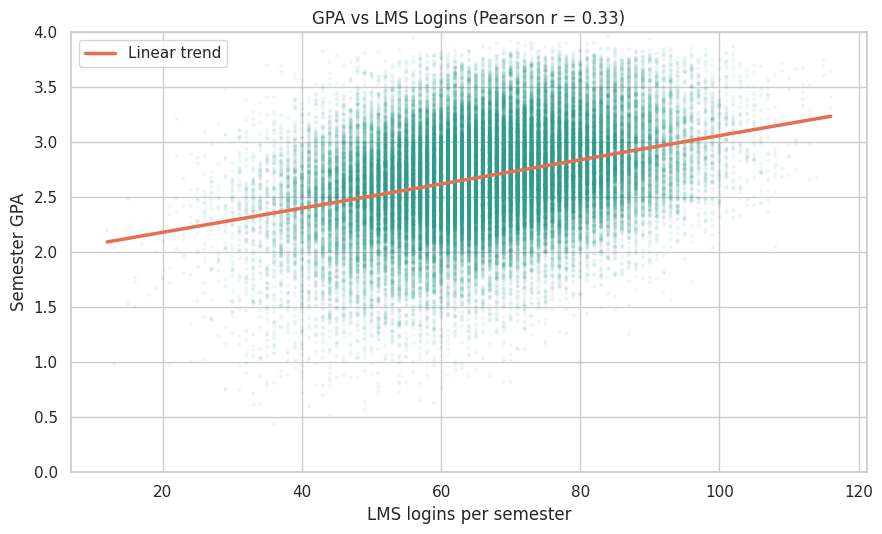

Observed student-semester records: 78,372
Pearson correlation: 0.331


In [26]:
# Compare GPA with observed LMS logins (exclude mean-filled values).
gpa_lms = df.loc[df['LMS_Logins_Missing'] == 0, ['LMS_Logins', 'Sem_GPA']].dropna()
lms_gpa_r = gpa_lms['LMS_Logins'].corr(gpa_lms['Sem_GPA'])

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.regplot(
        data=gpa_lms, x='LMS_Logins', y='Sem_GPA', ci=None,
        scatter_kws={'s': 8, 'alpha': 0.08, 'color': '#2A9D8F', 'edgecolors': 'none'},
        line_kws={'color': '#E76F51', 'linewidth': 2.5, 'label': 'Linear trend'},
        ax=ax,
    )
    ax.set(
        title=f'GPA vs LMS Logins (Pearson r = {lms_gpa_r:.2f})',
        xlabel='LMS logins per semester', ylabel='Semester GPA', ylim=(0, 4),
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

print(f'Observed student-semester records: {len(gpa_lms):,}')
print(f'Pearson correlation: {lms_gpa_r:.3f}')


The correlation between GPA and LMS Logins is approximately 0.33, indicating a moderate positive relationship: semesters with more LMS logins tend to have higher GPAs.

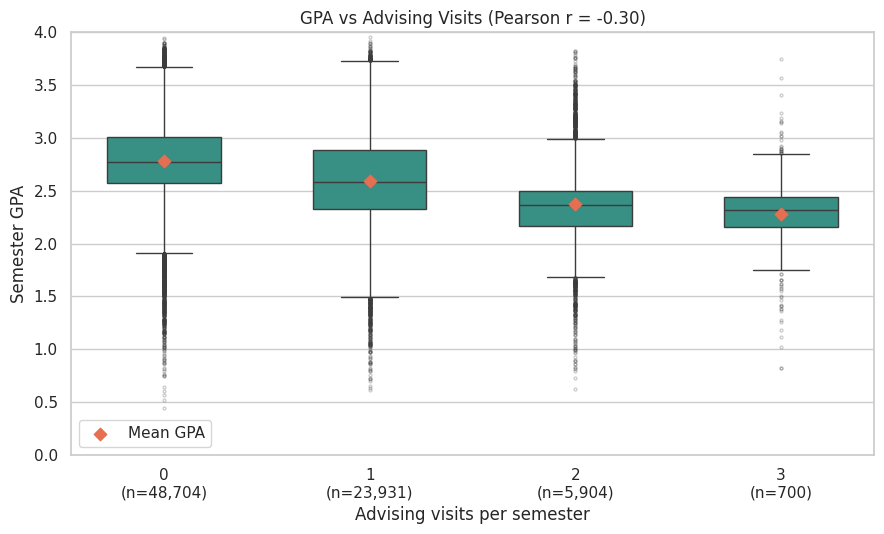

Pearson correlation: -0.305


,records,mean_gpa,median_gpa
Advising_Visits,,,
0,48704,2.782,2.77
1,23931,2.597,2.58
2,5904,2.376,2.37
3,700,2.278,2.32


In [27]:
# Compare GPA distributions across advising visit counts.
gpa_advising = df[['Advising_Visits', 'Sem_GPA']].dropna()
advising_gpa_summary = (
    gpa_advising.groupby('Advising_Visits')['Sem_GPA']
    .agg(records='size', mean_gpa='mean', median_gpa='median')
)
advising_gpa_r = gpa_advising['Advising_Visits'].corr(gpa_advising['Sem_GPA'])

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.boxplot(
        data=gpa_advising, x='Advising_Visits', y='Sem_GPA',
        order=advising_gpa_summary.index.tolist(), color='#2A9D8F', width=0.55,
        flierprops={'markersize': 2, 'alpha': 0.25}, ax=ax,
    )
    ax.scatter(
        np.arange(len(advising_gpa_summary)), advising_gpa_summary['mean_gpa'],
        color='#E76F51', marker='D', s=40, zorder=3, label='Mean GPA',
    )
    ax.set_xticks(np.arange(len(advising_gpa_summary)))
    ax.set_xticklabels([
        f'{visits}\n(n={row.records:,.0f})'
        for visits, row in advising_gpa_summary.iterrows()
    ])
    ax.set(
        title=f'GPA vs Advising Visits (Pearson r = {advising_gpa_r:.2f})',
        xlabel='Advising visits per semester', ylabel='Semester GPA', ylim=(0, 4),
    )
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()

print(f'Pearson correlation: {advising_gpa_r:.3f}')
display(advising_gpa_summary.round(3))


Mean GPA decreases from 2.78 for semesters with no advising visits to 2.60, 2.38, and 2.28 for 1, 2, and 3 visits, respectively. The correlation is approximately −0.30, indicating a moderate negative relationship.
This does not mean advising reduces GPA. One possible explanation is that students who are already struggling seek or are referred for more advising. These data do not establish why the relationship occurs or whether advising improves later outcomes.

,Records,Dropout_Events,Dropout_Percentage
Failed_Courses,,,
0,"34,762","1,853",5.33%
1,"23,878","2,653",11.11%
2,"7,736","1,712",22.13%
3,"1,522",574,37.71%
4,208,112,53.85%
5,18,13,72.22%


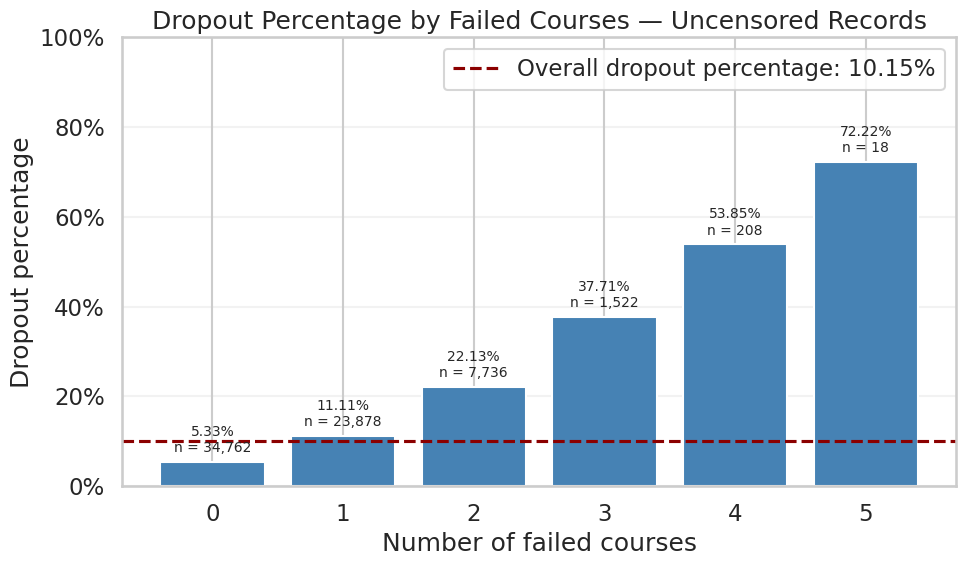

In [28]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Supporting table: uncensored student-semester records
failed_courses_summary = (
    df_dropout
    .groupby("Failed_Courses", observed=True)
    .agg(
        Records=("Target_Dropout_Next_Sem", "size"),
        Dropout_Events=("Target_Dropout_Next_Sem", "sum")
    )
    .sort_index()
)

failed_courses_summary["Dropout_Percentage"] = (
    failed_courses_summary["Dropout_Events"]
    / failed_courses_summary["Records"] * 100
)

display(
    failed_courses_summary.style.format({
        "Records": "{:,.0f}",
        "Dropout_Events": "{:,.0f}",
        "Dropout_Percentage": "{:.2f}%"
    })
)

# Dropout percentage chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    failed_courses_summary.index.astype(str),
    failed_courses_summary["Dropout_Percentage"],
    color="steelblue"
)

for bar, (_, row) in zip(bars, failed_courses_summary.iterrows()):
    ax.annotate(
        f'{row["Dropout_Percentage"]:.2f}%\n'
        f'n = {int(row["Records"]):,}',
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

overall_rate = df_dropout["Target_Dropout_Next_Sem"].mean() * 100

ax.axhline(
    overall_rate,
    color="darkred",
    linestyle="--",
    label=f"Overall dropout percentage: {overall_rate:.2f}%"
)

ax.set(
    title="Dropout Percentage by Failed Courses — Uncensored Records",
    xlabel="Number of failed courses",
    ylabel="Dropout percentage",
    ylim=(0, 100)
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

Failed courses show a strong relationship with the dropout target. The dropout percentage increases from 5.33% among records with no failed courses to 22.13% with two failed courses and 37.71% with three. The percentages for four and five failed courses are higher, but these groups contain only 208 and 18 records, respectively, so their estimates should be interpreted cautiously. These findings identify failed courses as a useful candidate predictor for the planned modeling phase; they do not establish causation. Counts represent student-semester records, and a student may appear more than once.

In [29]:
# Relationship between Financial Stress and 4 other features
# Pearson r: close to +1 = both go up together, close to -1 = one goes up while the other goes down, close to 0 = no relationship

features = ['Household_Size', 'Work_Hours', 'Family_Income', 'Sem_GPA']

# Print the correlation for each feature
for col in features:
    data = df[[col, 'Financial_Stress']].dropna()
    if col == 'Family_Income':
        data = df.loc[df['Family_Income_Missing'] == 0, [col, 'Financial_Stress']]  # skip median-filled incomes
    r, p = stats.pearsonr(data[col], data['Financial_Stress'])
    print(f"Financial stress vs {col}: r = {r:.2f}, p = {format_pvalue(p)}")

Financial stress vs Household_Size: r = 0.34, p = below numerical precision
Financial stress vs Work_Hours: r = 0.42, p = below numerical precision
Financial stress vs Family_Income: r = -0.42, p = below numerical precision
Financial stress vs Sem_GPA: r = -0.31, p = below numerical precision


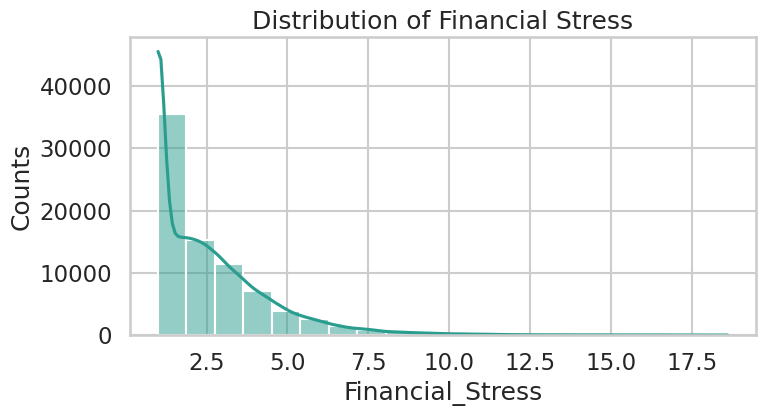

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='Financial_Stress', bins=20, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of Financial Stress', xlabel='Financial_Stress', ylabel='Counts')
plt.tight_layout()
plt.show()

In [31]:
# Check what it would a considered a high financial stress

# Keep only rows where we know what happened next semester
# Use the shared uncensored sample.
stress = df_dropout.copy()

# Split the stress group into bins
bins   = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, stress['Financial_Stress'].max()]
labels = ['0-1', '1-2', '2-3', '3-4', '4-5', '5-6', '6-7', '7-8', '8-9', '9-10', '10+']

stress['Stress_Group'] = pd.cut(stress['Financial_Stress'], bins=bins, labels=labels)
stress_dropout = (
    stress.groupby("Stress_Group", observed=True)[target]
    .agg(
        records="size",
        dropouts="sum",
        dropout_rate="mean",
    )
)

stress_dropout["dropout_rate"] *= 100
display(stress_dropout.round(2))

,records,dropouts,dropout_rate
Stress_Group,,,
0-1,18316,841,4.59
1-2,15010,976,6.50
2-3,13668,1261,9.23
3-4,9204,1167,12.68
4-5,5398,943,17.47
5-6,2907,597,20.54
6-7,1557,397,25.50
7-8,881,252,28.60
8-9,465,143,30.75


Students with a financial stress less than 3 are generally low risk candidates when it comes to continuing the studies next semester.

Students with a financial stress between 3 and 5 have expose more risk of dropping out (around 17%)

Students with a financial stress over 5 are most inclined to drop out, the rates for each stress level is above 20%. Moreover, as the financial stress goes up, so does the dropout rate (e.g. at financial stress level 8-9, the dropout rate for the next semester is 30%, meaning that 1 in 3 students found in this financial situation will drop out)

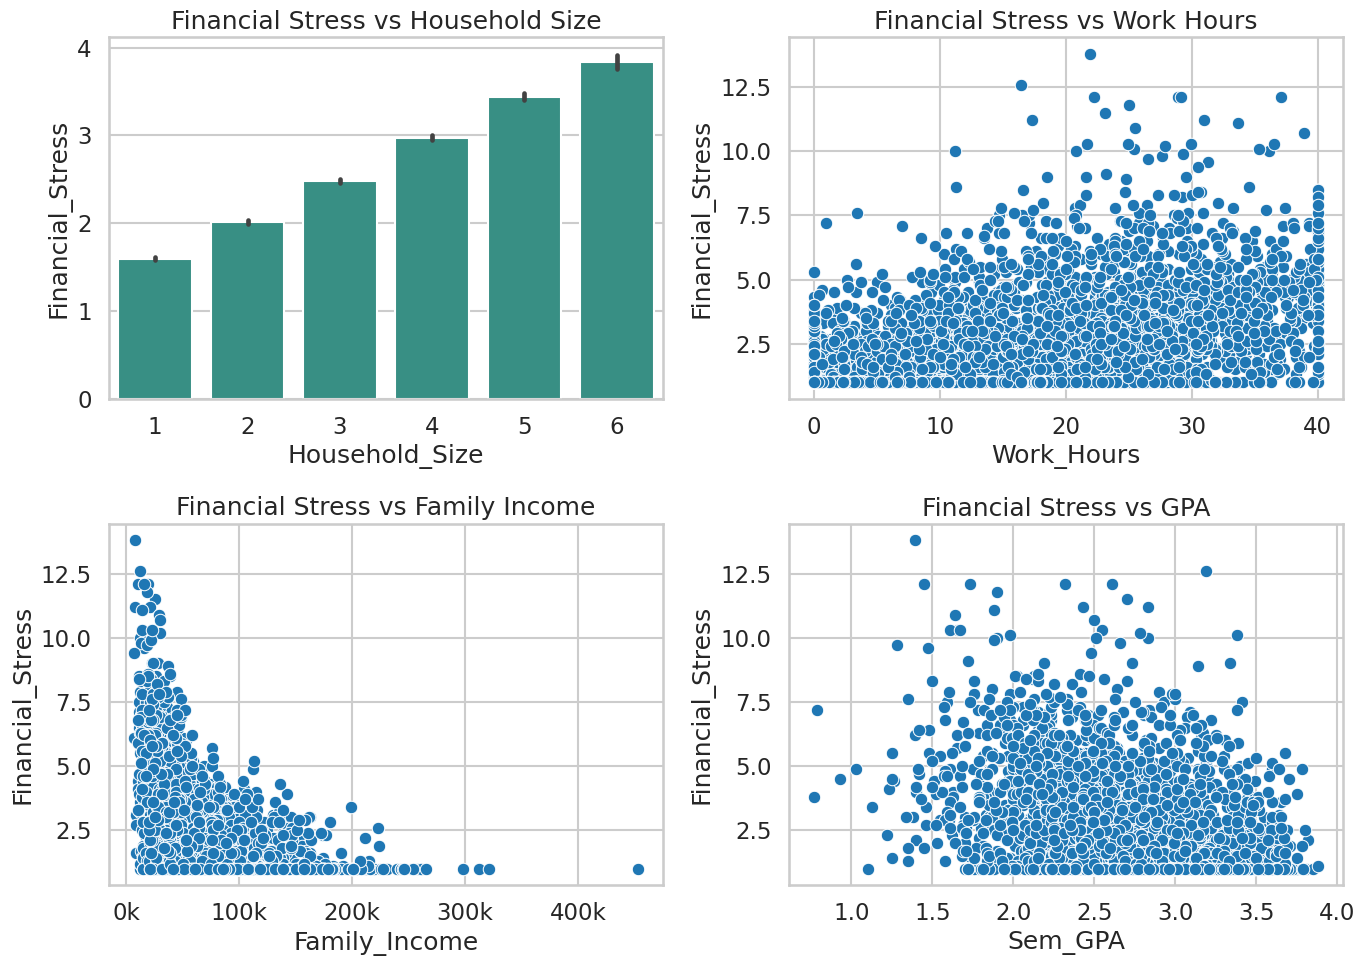

In [32]:
# Plot each relationship
sample = df.sample(frac=0.05, random_state=42)  # use 5% of rows so the scatter plots are readable

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Household size: average stress for each household size
sns.barplot(data=df, x='Household_Size', y='Financial_Stress', color='#2A9D8F', ax=axes[0, 0])
axes[0, 0].set_title('Financial Stress vs Household Size')

# 2-4) Scatter plot with a trend line
sns.scatterplot(data=sample, x='Work_Hours', y='Financial_Stress',
            ax=axes[0, 1])
axes[0, 1].set_title('Financial Stress vs Work Hours')

sns.scatterplot(data=sample[sample['Family_Income_Missing'] == 0],
            x='Family_Income', y='Financial_Stress',
            ax=axes[1, 0],
            )
axes[1, 0].set_title('Financial Stress vs Family Income')

sns.scatterplot(data=sample, x='Sem_GPA', y='Financial_Stress', ax=axes[1, 1])
axes[1, 1].set_title('Financial Stress vs GPA')

# Trim big income number such as 100.000 to 100k
axes[1, 0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1000:.0f}k'))

plt.tight_layout()
plt.show()

1. Household size increase financial stress.
2. Work hours also tend to have some candidates being found in the upper parts of the financial stress levels -> at less than 10-20 work hours usually the financial stress is below 4-5, but as the number of worked hours increases, more students appear to be financially struggling.
3. Financial stress is found only in the low family income zone.
4. When the level of financial stress is higher, it seems that the GPA tends to be smaller, but there are also cases of moderate to high financial stress and good GPA(above 3)

In [33]:
# create GPA and financial stress groups statistics
joint = df_dropout[
    ["Sem_GPA", "Financial_Stress", target]
].copy()

gpa_labels = [
    "0-2.0",
    ">2.0-2.5",
    ">2.5-3.0",
    ">3.0-4.0",
]

stress_labels = [
    "0-2",
    ">2-4",
    ">4-6",
    ">6",
]

joint["GPA_Group"] = pd.cut(
    joint["Sem_GPA"],
    bins=[0, 2, 2.5, 3, 4],
    labels=gpa_labels,
    include_lowest=True,
)

joint["Stress_Group"] = pd.cut(
    joint["Financial_Stress"],
    bins=[0, 2, 4, 6, np.inf],
    labels=stress_labels,
    include_lowest=True,
)

joint_summary = (
    joint.groupby(
        ["GPA_Group", "Stress_Group"],
        observed=False,
    )[target]
    .agg(
        records="size",
        dropouts="sum",
        dropout_pct="mean",
    )
    .reset_index()
)

joint_summary["dropout_pct"] *= 100

print(f"Records included: {joint_summary['records'].sum():,}")
print(f"Dropout events: {joint_summary['dropouts'].sum():,}")

display(joint_summary.round({"dropout_pct": 2}))

Records included: 68,124
Dropout events: 6,917


,GPA_Group,Stress_Group,records,dropouts,dropout_pct
0,0-2.0,0-2,735,185,25.17
1,0-2.0,>2-4,1290,456,35.35
2,0-2.0,>4-6,973,423,43.47
3,0-2.0,>6,860,470,54.65
4,>2.0-2.5,0-2,5699,535,9.39
5,>2.0-2.5,>2-4,6509,964,14.81
6,>2.0-2.5,>4-6,3232,683,21.13
7,>2.0-2.5,>6,1403,453,32.29
8,>2.5-3.0,0-2,17811,906,5.09
9,>2.5-3.0,>2-4,10655,864,8.11


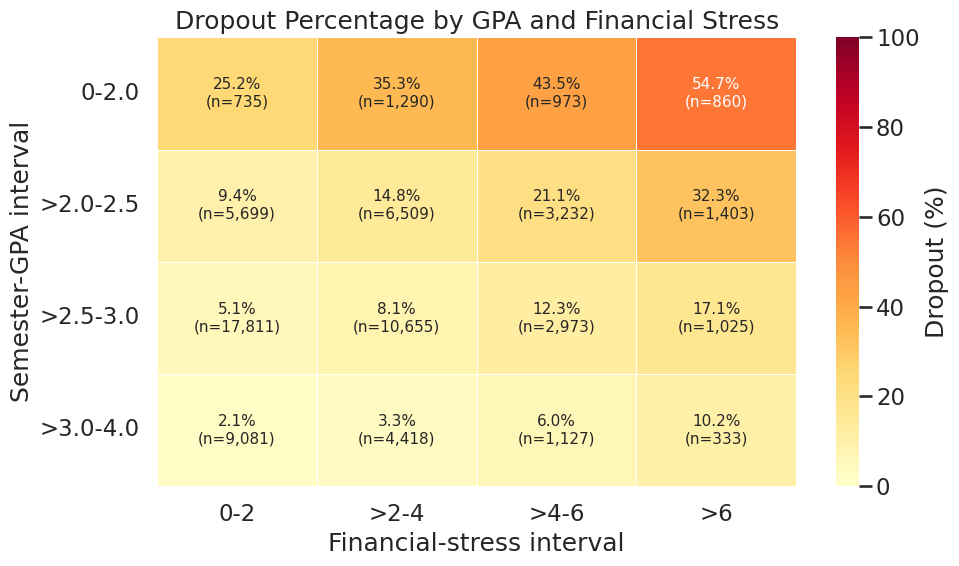

In [34]:
rates = (
    joint_summary.pivot(
        index="GPA_Group",
        columns="Stress_Group",
        values="dropout_pct",
    )
    .reindex(index=gpa_labels, columns=stress_labels)
)

counts = (
    joint_summary.pivot(
        index="GPA_Group",
        columns="Stress_Group",
        values="records",
    )
    .reindex(index=gpa_labels, columns=stress_labels)
    .fillna(0)
    .astype(int)
)

annotations = np.full(rates.shape, "", dtype=object)

for row in range(rates.shape[0]):
    for col in range(rates.shape[1]):
        rate = rates.iloc[row, col]
        count = counts.iloc[row, col]

        if pd.notna(rate):
            annotations[row, col] = (
                f"{rate:.1f}%\n"
                f"(n={count:,})"
            )

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    rates,
    mask=rates.isna(),
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 11},
    cbar_kws={"label": "Dropout (%)"},
    ax=ax,
)

ax.set(
    title="Dropout Percentage by GPA and Financial Stress",
    xlabel="Financial-stress interval",
    ylabel="Semester-GPA interval",
)

ax.set_facecolor("#E6E6E6")
ax.grid(False)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

This heatmap represents a comparison for dropout percentange and 2 features (GPA and financial stress) broken by groups. Within each GPA band, observed dropout percentages increase across financial-stress groups. For example, among records with GPA greater than 3.0, dropout percentages increase from 2.10% in the lowest stress group to 10.21% in the highest. This suggests that GPA alone does not capture all observed differences in dropout. The comparisons are descriptive associations within broad groups and do not establish causal effects.

,r,Strength |r|,Direction
Sem_GPA,-0.273,0.273,↓ dropout
Financial_Stress,0.231,0.231,↑ dropout
Failed_Courses,0.231,0.231,↑ dropout
Work_Hours,0.134,0.134,↑ dropout
Attendance,-0.102,0.102,↓ dropout
Family_Income,-0.098,0.098,↓ dropout
LMS_Logins,-0.093,0.093,↓ dropout
Advising_Visits,0.074,0.074,↑ dropout
Scholarship,-0.058,0.058,↓ dropout
Emergency_Expense,0.003,0.003,↑ dropout


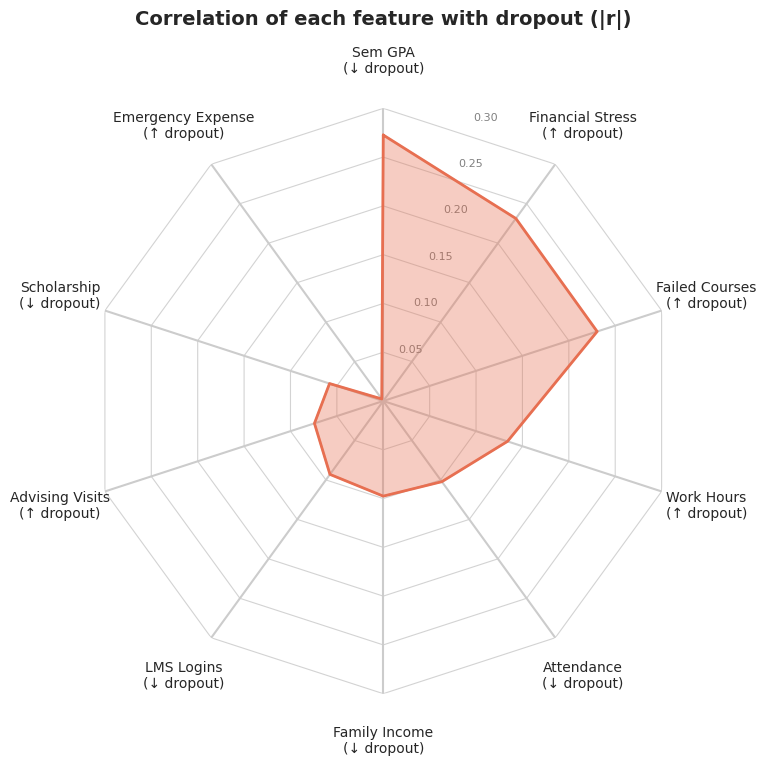

In [35]:
features = ['Financial_Stress', 'Family_Income', 'Sem_GPA', 'LMS_Logins',
            'Failed_Courses', 'Work_Hours', 'Attendance', 'Advising_Visits',
            'Emergency_Expense', 'Scholarship']

# Use the shared uncensored sample for dropout-related analysis.
data = df_dropout

# Correlation of each feature with dropout, straight from the data
corr_with_dropout = data[features].corrwith(data[target])

result = pd.DataFrame({
    'r': corr_with_dropout,
    'Strength |r|': corr_with_dropout.abs(),
    'Direction': np.where(corr_with_dropout > 0, '↑ dropout', '↓ dropout'),
}).sort_values('Strength |r|', ascending=False)
display(result.round(3))

# ---- Radar chart ----
labels = [f"{f.replace('_', ' ')}\n({d})" for f, d in zip(result.index, result['Direction'])]
values = result['Strength |r|'].tolist()

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]   # repeat the first point to close the shape
values += values[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
ax.plot(angles, values, color='#E76F51', linewidth=2)
ax.fill(angles, values, color='#E76F51', alpha=0.35)

ax.set_theta_offset(np.pi / 2)   # first feature at the top
ax.set_theta_direction(-1)       # go clockwise
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)
ax.tick_params(axis='x', pad=18)

# Spider-web style grid: polygons instead of circles
rings = np.arange(0.05, max(values) + 0.05, 0.05)
ax.set_ylim(0, rings[-1])
ax.set_yticks(rings)
ax.set_yticklabels([f'{r:.2f}' for r in rings], fontsize=8, color='grey')
ax.set_rlabel_position(360 / len(labels) / 2)
ax.yaxis.grid(False)
ax.spines['polar'].set_visible(False)
for r in rings:
    ax.plot(angles, [r] * len(angles), color='lightgrey', linewidth=0.8, zorder=0)

ax.set_title('Correlation of each feature with dropout (|r|)',
             fontsize=14, fontweight='bold', pad=60)
plt.tight_layout()
plt.show()

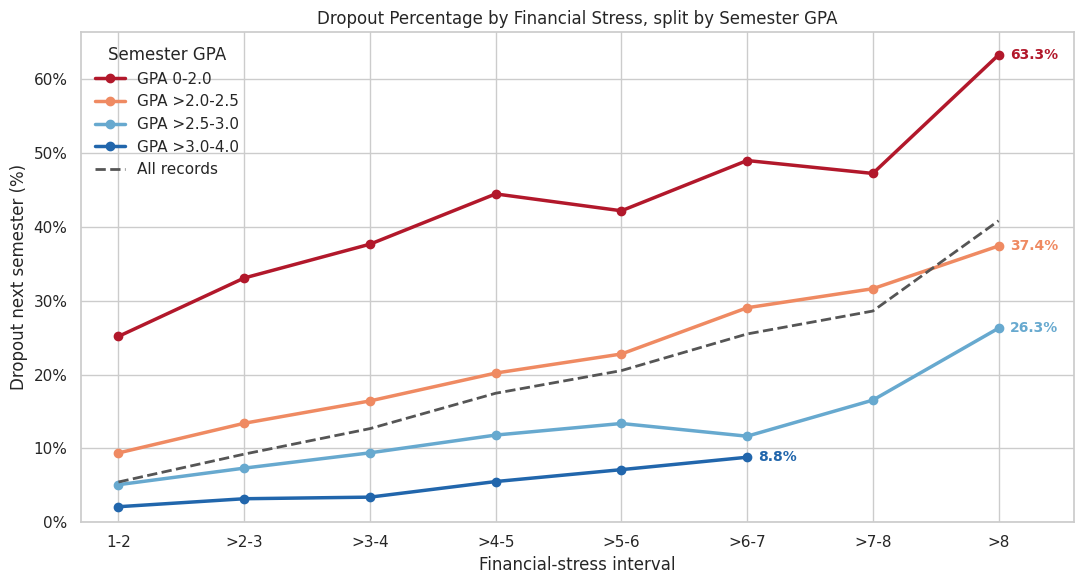

Stress_Group,1-2,>2-3,>3-4,>4-5,>5-6,>6-7,>7-8,>8
GPA_Group,,,,,,,,
GPA 0-2.0,25.17,33.08,37.66,44.46,42.18,48.99,47.24,63.29
GPA >2.0-2.5,9.39,13.40,16.43,20.20,22.79,29.05,31.63,37.41
GPA >2.5-3.0,5.09,7.33,9.40,11.81,13.38,11.65,16.54,26.28
GPA >3.0-4.0,2.10,3.18,3.40,5.51,7.12,8.81,NaN,NaN


In [36]:
# Line chart: how dropout percentage changes with financial stress, one line per GPA band
line_data = df_dropout[["Sem_GPA", "Financial_Stress", target]].copy()

line_gpa_labels = ["GPA 0-2.0", "GPA >2.0-2.5", "GPA >2.5-3.0", "GPA >3.0-4.0"]
line_data["GPA_Group"] = pd.cut(
    line_data["Sem_GPA"],
    bins=[0, 2, 2.5, 3, 4],
    labels=line_gpa_labels,
    include_lowest=True,
)

# 1-point stress intervals (stress starts at 1); everything above 8 grouped together
stress_bins = [1, 2, 3, 4, 5, 6, 7, 8, np.inf]
stress_line_labels = ["1-2", ">2-3", ">3-4", ">4-5", ">5-6", ">6-7", ">7-8", ">8"]
line_data["Stress_Group"] = pd.cut(
    line_data["Financial_Stress"],
    bins=stress_bins,
    labels=stress_line_labels,
    include_lowest=True,
)

line_summary = (
    line_data.groupby(["GPA_Group", "Stress_Group"], observed=False)[target]
    .agg(records="size", dropouts="sum", dropout_pct="mean")
    .reset_index()
)
line_summary["dropout_pct"] *= 100

# Hide points backed by too few records to be reliable
MIN_RECORDS = 100
line_summary.loc[line_summary["records"] < MIN_RECORDS, "dropout_pct"] = np.nan

# Overall line (all GPA bands together) for reference
overall_line = (
    line_data.groupby("Stress_Group", observed=False)[target]
    .mean()
    .mul(100)
    .reindex(stress_line_labels)
)

line_colors = ["#B2182B", "#EF8A62", "#67A9CF", "#2166AC"]  # low GPA = red, high GPA = blue
x_positions = np.arange(len(stress_line_labels))

with sns.axes_style("whitegrid"), sns.plotting_context("notebook"):
    fig, ax = plt.subplots(figsize=(11, 6))

    for label, color in zip(line_gpa_labels, line_colors):
        group = (
            line_summary.loc[line_summary["GPA_Group"] == label]
            .set_index("Stress_Group")
            .reindex(stress_line_labels)
        )
        ax.plot(
            x_positions, group["dropout_pct"],
            marker="o", linewidth=2.5, markersize=6,
            color=color, label=label,
        )
        # Label the last visible point with its rate
        last = group["dropout_pct"].last_valid_index()
        if last is not None:
            ax.annotate(
                f"{group.loc[last, 'dropout_pct']:.1f}%",
                (stress_line_labels.index(last), group.loc[last, "dropout_pct"]),
                xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=10, color=color, fontweight="bold",
            )

    ax.plot(
        x_positions, overall_line,
        linestyle="--", linewidth=2, color="#555555", label="All records",
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(stress_line_labels)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_ylim(bottom=0)
    ax.set_xlim(-0.3, len(stress_line_labels) - 0.4)
    ax.set(
        title="Dropout Percentage by Financial Stress, split by Semester GPA",
        xlabel="Financial-stress interval",
        ylabel="Dropout next semester (%)",
    )
    ax.legend(title="Semester GPA", frameon=False, loc="upper left")

    plt.tight_layout()
    plt.show()

# Supporting table: dropout % per GPA band (rows) and stress interval (columns)
display(
    line_summary.pivot(index="GPA_Group", columns="Stress_Group", values="dropout_pct")
    .round(2)
)